# Same Size, Different Damage: Why Some Earthquakes Hit Harder Than Others

**DS 3000 Project Proposal:**
Nadim-Marc El Achkar

## Part 1: The Problem

When an earthquake hits, the first number we hear on the news is the magnitude. But the magnitude does not tell the whole story.

Here is an example I found in my data. In 2024, a **magnitude 6.8** earthquake hit near the Kuril Islands. Only 3 people reported feeling it, and the USGS gave it a green alert, which means little or no damage expected. In 2023, an earthquake of the exact same size, **magnitude 6.8**, hit the Atlas Mountains in Morocco. Almost 2,000 people reported feeling it, it got a red alert, and thousands of people died.

So why can two earthquakes of the same size end so differently?

The USGS explains that the size of an earthquake and the shaking people feel are two different things:

> "Magnitude is the size of the earthquake. An earthquake has a single magnitude. The shaking that it causes has many values that vary from place to place based on distance, type of surface material, and other factors." (USGS, *Earthquake Magnitude, Energy Release, and Shaking Intensity*)

One big difference between my two examples is depth. The Kuril Islands earthquake started about 146 km underground. The Morocco earthquake was much shallower. The USGS wrote about Morocco:

> "The magnitude 6.8 earthquake in the Atlas Mountains on September 8 has taken a sobering toll on human life and property in a part of western Morocco that is not prone to frequent earthquakes." (USGS, *Major earthquake strikes Oukaïmedene, Morocco*, 2023)

I grew up in the Middle East, and earthquakes like the ones in Morocco in 2023 and Turkey and Syria in 2023 were big news for people around me. I want to use data to understand what actually makes an earthquake dangerous, beyond the one number we always hear.

### My two questions

1. **How much do magnitude and depth tell us about how strong the shaking will be?** If I know how big and how deep an earthquake is, can I predict how hard the ground shakes?
2. **Can I predict which earthquakes get a warning alert (yellow, orange, or red) instead of a green alert?** The USGS gives each big earthquake a color based on the expected deaths and money lost. I want to see how well magnitude, depth, and shaking can predict that color.

### Sources
1. U.S. Geological Survey. *Earthquake Magnitude, Energy Release, and Shaking Intensity.* https://www.usgs.gov/programs/earthquake-hazards/earthquake-magnitude-energy-release-and-shaking-intensity
2. U.S. Geological Survey (September 9, 2023). *Major earthquake strikes Oukaïmedene, Morocco.* https://www.usgs.gov/news/featured-story/major-earthquake-strikes-oukaimedene-morocco

## Part 2: The Data

**Source:** USGS Earthquake Catalog API
Documentation: https://earthquake.usgs.gov/fdsnws/event/1/

The API is free and does not need a key. I send it a start date, an end date, and a minimum magnitude, and it sends back JSON (in a format called GeoJSON). Each earthquake comes back as one "feature" with its details.

I am pulling every earthquake of **magnitude 6.0 or higher from 2020 to 2025**. That gives several hundred earthquakes, which is way more than the 30 rows needed. I stop at the end of 2025 because the USGS keeps updating the shaking and alert values for a while after an earthquake, so the newest ones may not have final numbers yet.

The columns I will keep:

| Column | Type | What it means |
|---|---|---|
| `mag` | numeric | Magnitude (size of the earthquake) |
| `depth_km` | numeric | How deep underground it started |
| `mmi` | numeric | Estimated strongest shaking (Modified Mercalli Intensity, 1 to 10) |
| `felt` | numeric | Number of people who reported feeling it to the USGS |
| `sig` | numeric | USGS significance score |
| `alert` | categorical | USGS PAGER alert color: green, yellow, orange, red |
| `mag_type` | categorical | Method used to measure the magnitude |
| `tsunami` | categorical | 1 if it happened in an ocean region, 0 if not |

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Step 1: Call the API

In [2]:
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

params = {
    "format": "geojson",
    "starttime": "2020-01-01",
    "endtime": "2025-12-31",
    "minmagnitude": 6,
}

response = requests.get(url, params=params)
print(response.status_code)   # 200 means it worked

data = response.json()
print(data.keys())
print("Number of earthquakes:", data["metadata"]["count"])

200
dict_keys(['type', 'metadata', 'features', 'bbox'])
Number of earthquakes: 795


### Step 2: Look at one earthquake

Before building a table I want to see what one earthquake looks like in the JSON.

In [3]:
first_quake = data["features"][0]
print(first_quake["properties"]["title"])
print(first_quake["properties"].keys())
print(first_quake["geometry"]["coordinates"])   # [longitude, latitude, depth in km]

M 6.2 - 43 km W of Puerto Santa, Peru
dict_keys(['mag', 'place', 'time', 'updated', 'tz', 'url', 'detail', 'felt', 'cdi', 'mmi', 'alert', 'status', 'tsunami', 'sig', 'net', 'code', 'ids', 'sources', 'types', 'nst', 'dmin', 'rms', 'gap', 'magType', 'type', 'title'])
[-79.039, -8.9834, 58]


### Step 3: Turn the JSON into a DataFrame

The details I want are in `properties`, but the depth is inside `geometry`, so I loop through each earthquake and grab what I need.

In [4]:
rows = []

for quake in data["features"]:
    props = quake["properties"]
    coords = quake["geometry"]["coordinates"]

    rows.append({
        "place": props["place"],
        "time": props["time"],
        "mag": props["mag"],
        "depth_km": coords[2],
        "longitude": coords[0],
        "latitude": coords[1],
        "mmi": props["mmi"],
        "felt": props["felt"],
        "sig": props["sig"],
        "alert": props["alert"],
        "mag_type": props["magType"],
        "tsunami": props["tsunami"],
    })

quakes = pd.DataFrame(rows)

# Time comes in milliseconds, so I change it to a normal date
quakes["time"] = pd.to_datetime(quakes["time"], unit="ms")

quakes.head()

,place,time,mag,depth_km,longitude,latitude,mmi,felt,sig,alert,mag_type,tsunami
0,"43 km W of Puerto Santa, Peru",2025-12-28 02:51:49.922,6.2,58.0,-79.0390,-8.9834,5.844,76.0,693,yellow,mww,0
1,"29 km ESE of Yilan, Taiwan",2025-12-27 15:05:55.388,6.6,63.0,122.0354,24.6841,6.114,439.0,916,green,mww,1
2,"2025 Taitung, Taiwan Earthquake",2025-12-24 09:47:06.669,6.0,8.0,121.2494,22.8982,6.707,61.0,600,green,mww,0
3,"45 km NNE of Goroka, Papua New Guinea",2025-12-22 10:31:27.918,6.5,107.0,145.5368,-5.7036,6.039,12.0,657,green,mww,0
4,"117 km NE of Kuji, Japan",2025-12-12 02:44:12.841,6.7,19.0,142.8131,40.8899,4.761,21.0,701,green,mww,1


### Step 4: Save it so I don't have to call the API every time

In [5]:
quakes.to_csv("earthquakes_2020_2025.csv", index=False)
print(quakes.shape)

(795, 12)


### Step 5: First look at the data

In [6]:
quakes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 795 entries, 0 to 794
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   place      795 non-null    object        
 1   time       795 non-null    datetime64[ns]
 2   mag        795 non-null    float64       
 3   depth_km   795 non-null    float64       
 4   longitude  795 non-null    float64       
 5   latitude   795 non-null    float64       
 6   mmi        794 non-null    float64       
 7   felt       654 non-null    float64       
 8   sig        795 non-null    int64         
 9   alert      794 non-null    object        
 10  mag_type   795 non-null    object        
 11  tsunami    795 non-null    int64         
dtypes: datetime64[ns](1), float64(6), int64(2), object(3)
memory usage: 74.7+ KB


In [7]:
quakes.describe().round(2)

,time,mag,depth_km,longitude,latitude,mmi,felt,sig,tsunami
count,795,795.00,795.00,795.00,795.00,794.00,654.00,795.00,795.00
mean,2022-12-20 23:42:59.810094336,6.38,77.27,38.79,0.28,4.59,254.13,726.27,0.31
min,2020-01-07 06:05:19.759000,6.00,2.70,-179.96,-69.77,0.00,0.00,554.00,0.00
25%,2021-07-03 10:51:56.820000,6.10,10.00,-74.18,-22.45,3.64,3.00,573.00,0.00
50%,2022-11-22 02:37:57.528999936,6.20,21.00,102.24,-3.54,4.61,15.00,620.00,0.00
75%,2024-06-05 00:55:15.152000,6.60,62.24,145.68,24.31,6.17,80.75,730.50,1.00
max,2025-12-28 02:51:49.922000,8.80,660.00,180.00,71.18,9.95,25987.00,2910.00,1.00
std,NaN,0.42,138.56,125.54,31.51,2.28,1654.27,323.17,0.46


In [8]:
# How many earthquakes got each alert color?
quakes["alert"].value_counts(dropna=False)

alert
green     693
yellow     60
orange     23
red        18
None        1
Name: count, dtype: int64

In [9]:
# Missing values in each column
quakes.isna().sum()

place          0
time           0
mag            0
depth_km       0
longitude      0
latitude       0
mmi            1
felt         141
sig            0
alert          1
mag_type       0
tsunami        0
dtype: int64

### Checking my two examples

Here are the two magnitude 6.8 earthquakes from Part 1, pulled straight from the data.

In [10]:
examples = quakes[(quakes["mag"] == 6.8) &
                  (quakes["place"].str.contains("Kuril|Morocco", na=False))]
examples[["place", "time", "mag", "depth_km", "mmi", "felt", "alert"]]

,place,time,mag,depth_km,mmi,felt,alert
55,"123 km E of Severo-Kuril’sk, Russia",2025-08-03 05:37:55.148,6.8,30.0,6.881,7.0,green
144,Kuril Islands,2024-12-27 12:47:37.696,6.8,146.0,5.155,3.0,green
294,"Al Haouz, Morocco",2023-09-08 22:11:01.405,6.8,19.0,8.459,1988.0,red


### A few quick charts

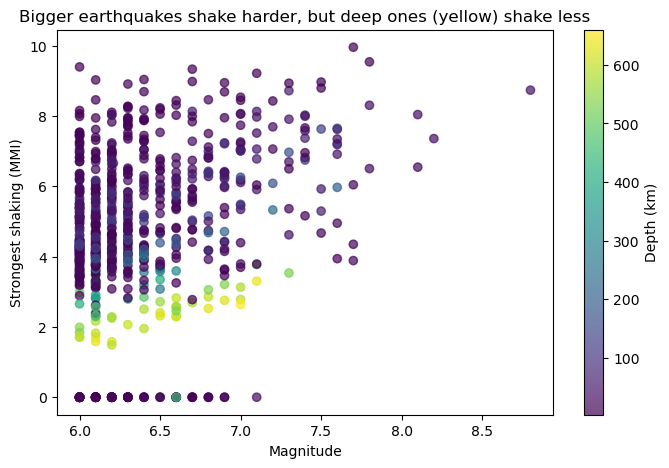

In [11]:
# Question 1: magnitude vs shaking, colored by depth
plt.figure(figsize=(8, 5))
plt.scatter(quakes["mag"], quakes["mmi"], c=quakes["depth_km"], cmap="viridis", alpha=0.7)
plt.colorbar(label="Depth (km)")
plt.xlabel("Magnitude")
plt.ylabel("Strongest shaking (MMI)")
plt.title("Bigger earthquakes shake harder, but deep ones (yellow) shake less")
plt.show()

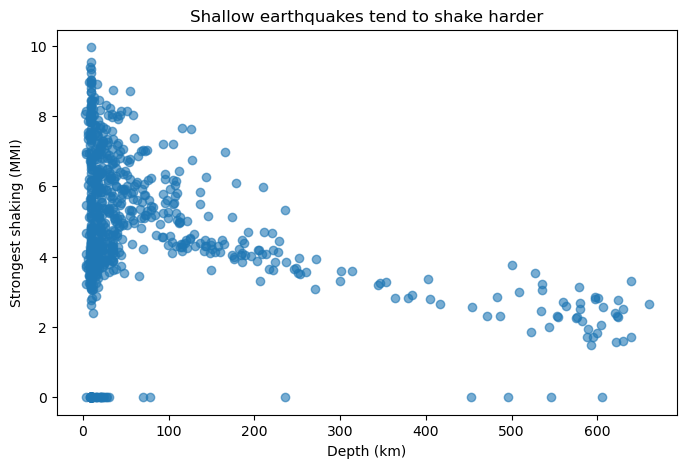

In [12]:
# Depth vs shaking
plt.figure(figsize=(8, 5))
plt.scatter(quakes["depth_km"], quakes["mmi"], alpha=0.6)
plt.xlabel("Depth (km)")
plt.ylabel("Strongest shaking (MMI)")
plt.title("Shallow earthquakes tend to shake harder")
plt.show()

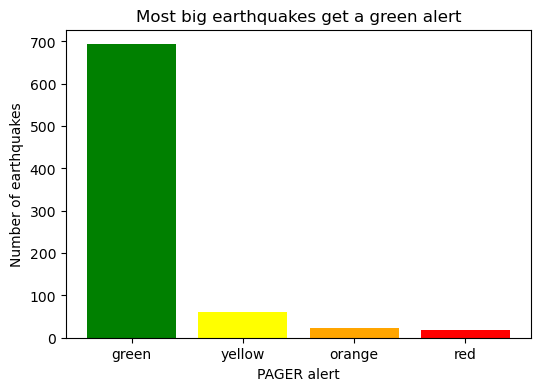

In [13]:
# Question 2: how many earthquakes got each alert color
order = ["green", "yellow", "orange", "red"]
counts = quakes["alert"].value_counts().reindex(order).fillna(0)

plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values, color=order)
plt.xlabel("PAGER alert")
plt.ylabel("Number of earthquakes")
plt.title("Most big earthquakes get a green alert")
plt.show()

In [14]:
# Average magnitude, depth, and shaking for each alert color
quakes.groupby("alert")[["mag", "depth_km", "mmi"]].mean().reindex(order).round(2)

,mag,depth_km,mmi
alert,,,
green,6.33,84.86,4.13
yellow,6.60,31.70,7.38
orange,6.57,16.49,8.11
red,7.04,16.97,8.60


## Part 3: How I Will Use the Data

For **Question 1**, the shaking (`mmi`) is a number, so this is a regression problem. I will use magnitude and depth to predict the shaking, starting with linear regression. If the model does well, it means size and depth explain most of the shaking. If it does poorly, it means other things matter a lot too, like the type of ground, which the USGS source mentions. I can also look at which feature matters more: making an earthquake bigger or making it shallower.

For **Question 2**, the alert color is a category, so this is a classification problem. Since most earthquakes are green, I will group yellow, orange, and red together as "warning" and try to predict green vs warning using magnitude, depth, and shaking. I will try a classifier like k nearest neighbors or a decision tree and check the results with a confusion matrix. The USGS alert also depends on how many people live nearby and how strong the buildings are, which I do not have in my data. So how well my model does will show how much of the danger comes from the earthquake itself and how much comes from where it happens.

Before building the models I will drop rows with no `mmi` or no `alert`, and check for outliers.